In [1]:
# Colab only: clone the repo and move into the project root
import os
import sys

# Check if running in Google Colab
if 'google.colab' in sys.modules:
    # Clone repository if it hasn't been cloned yet
    if not os.path.exists('/content/convolutional_vae_quishing'):
        !git clone https://github.com/AnhJoe/convolutional_vae_quishing.git

    # Change working directory to the project root
    os.chdir('/content/convolutional_vae_quishing')

In [2]:
# Local only: find the project root (the folder containing src/) and add it to the import path
# For local runs. Else if running Colab, skip this.

import sys
from pathlib import Path

# Set to root for src load
root = Path.cwd()
while root != root.parent and not (root / "src").exists():
    root = root.parent

if not (root / "src").exists():
    raise FileNotFoundError("Could not find 'src' folder above current working directory.")

sys.path.insert(0, str(root))
print("Project root:", root)

Project root: c:\Users\joetn\convolutional_vae_quishing


# Load Data

In [3]:
# Imports for downloading and extracting the dataset
import os
import tempfile
import zipfile
from pathlib import Path

import gdown

In [4]:
# Download the dataset from Google Drive into data/raw unless it is already there
# Colab will require this run for every fresh kernel runtime
# Local runs save datasets to data/raw

DRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1i5dQyllOAbZAM4XvXrJ0d1MuUuJMGVeb?usp=sharing"

root = globals().get("root", Path.cwd())
RAW_DIR = root / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

# Written after a complete download and extraction so a partial run is never mistaken for a finished one
EXTRACT_MARKER = RAW_DIR / ".extracted"


def extract_zip(zip_path: Path, dest: Path) -> Path:
    """Extract a zip into dest, skipping files that already exist with the same size.
    The folders inside the zip (QR_All_benign, QR_All_Malicious) land directly in dest,
    so the zip's own name never appears in the path. Only if an archive has loose files
    at its root is it nested under a folder named after the zip."""
    with zipfile.ZipFile(zip_path) as zf:
        infos = [i for i in zf.infolist() if not i.filename.startswith("__MACOSX")]
        tops = sorted({i.filename.split("/")[0] for i in infos if i.filename.strip("/")})
        loose_files = any(not i.is_dir() and "/" not in i.filename for i in infos)
        target = dest / zip_path.stem if loose_files else dest
        target.mkdir(parents=True, exist_ok=True)

        new, skipped = 0, 0
        for info in infos:
            out = target / info.filename
            if info.is_dir():
                out.mkdir(parents=True, exist_ok=True)
            elif out.exists() and out.stat().st_size == info.file_size:
                skipped += 1
            else:
                zf.extract(info, target)
                new += 1
    print(f"{zip_path.name}: top-level {tops}, {new:,} files extracted, {skipped:,} already present")
    return target


if EXTRACT_MARKER.exists():
    print(f"data/raw already loaded, skipping download: {RAW_DIR}")
else:
    with tempfile.TemporaryDirectory() as tmp:
        downloaded = gdown.download_folder(url=DRIVE_FOLDER_URL, output=tmp, quiet=False, use_cookies=False)
        zips = [Path(f) for f in (downloaded or []) if str(f).lower().endswith(".zip")]
        if not zips:
            raise FileNotFoundError("No zip files were downloaded. Check the Drive folder sharing settings.")
        for z in zips:
            extract_zip(z, RAW_DIR)
    EXTRACT_MARKER.touch()

data/raw already loaded, skipping download: c:\Users\joetn\convolutional_vae_quishing\data\raw


# Exploratory Data Analysis (EDA)

The goal of this section is to decide, from evidence without assumptions, how the data should be cleaned, transformed, and feature engineered before any model is trained. Each subsection asks one question, shows a plot or table, and ends with the decision it supports.

Plan:
1. Inventory and label integrity (can the labels be trusted, are the CSV rows consistent)
2. Class balance and URL duplicates
3. URL structure and the confounds it carries
4. Confound strength (how much a trivial feature separates the classes on its own)
5. Splitting and leakage
6. Cleaning log, transformations, feature candidates and floor definitions, then the processed manifest

All analysis uses every URL.

In [5]:
# Imports, settings (seed, colours, plot style), the paths to the two class folders and a table helper
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

root = globals().get("root", Path.cwd())
RAW_DIR = globals().get("RAW_DIR", root / "data" / "raw")
PROC_DIR = root / "data" / "processed"
PROC_DIR.mkdir(parents=True, exist_ok=True)

SEED = 0

COLORS = {"benign": "#2a7ab9", "malicious": "#d1495b"}
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False})

CLASS_DIR = {"benign": RAW_DIR / "QR_All_benign", "malicious": RAW_DIR / "QR_All_Malicious"}

def show_table(df, title, precision=3):
    """Show a DataFrame with a title above it, thousands separators, and long text wrapped inside the cells."""
    styled = (df.style.format(precision=precision, thousands=",", na_rep="NaN").set_caption(title)
              .set_table_styles([
                  {"selector": "caption", "props": [("caption-side", "top"), ("text-align", "left"), ("font-weight", "bold"), ("padding", "4px 0 8px 0")]},
                  {"selector": "th, td", "props": [("white-space", "normal"), ("overflow-wrap", "anywhere"), ("max-width", "460px"), ("vertical-align", "top")]},
              ]))
    display(styled)

## 1. Inventory and label integrity

Question: can the class label be trusted, and are the CSV rows consistent? The malicious CSV rows point to files called `benign_XXXXXX.png`, so the `qr_path` text must be checked before it is trusted.

In [6]:
# Load both CSVs into one table, taking the class label from the folder
frames = []
for cls, d in CLASS_DIR.items():
    csv_path = next(d.glob("all_generated_urls_*.csv"))
    f = pd.read_csv(csv_path, keep_default_na=False)   # keep strings such as "NA" or "null" as text
    csv_columns = list(f.columns)                       # columns the CSVs come with, before the notebook adds its own
    f["cls"] = cls
    frames.append(f)
raw = pd.concat(frames, ignore_index=True)
raw["label"] = (raw["cls"] == "malicious").astype("int8")   # 1 = malicious, taken from the folder the CSV lives in
parts = raw["qr_path"].str.replace("\\", "/", regex=False).str.split("/")
raw["csv_folder"] = parts.str[-3]
print(f"{len(raw):,} rows. CSV columns: {csv_columns}")

1,005,738 rows. CSV columns: ['index', 'url', 'qr_path']


In [7]:
# Integrity checks: are the indexes consistent, and does each CSV sit in the folder that its qr_path names?
rows = []
for cls in CLASS_DIR:
    sub = raw[raw["cls"] == cls]
    rows.append({
        "class (folder)": cls,
        "csv rows": len(sub),
        "index unique": bool(sub["index"].is_unique),
        "folder named inside qr_path": ", ".join(sorted(sub["csv_folder"].unique())),
    })
integrity = pd.DataFrame(rows).set_index("class (folder)").T
show_table(integrity, "Integrity checks per class folder")

class (folder),benign,malicious
csv rows,"429,976","575,762"
index unique,True,True
folder named inside qr_path,QR_All_benign,QR_All_Malicious


**Findings and decision (labels).** The CSVs have three columns (`index`, `url`, `qr_path`) and no label column, so the class is recorded only by the folder that holds the CSV, and the label is taken from there. The index is unique within each class (429,976 benign and 575,762 malicious rows), and the folder named inside `qr_path` matches the folder that holds the CSV in both classes.

The malicious `qr_path` values also point to files called `benign_*.png`, so neither the path nor the file name carries a label. The labels are created from the folder name.

## 2. Class balance and URL duplicates

Questions: how imbalanced is the collection, and does the same URL appear more than once, inside a class or across classes? Duplicates matter twice. Across classes they make the label ambiguous. Within a class they let a train/test split leak identical items.

In [8]:
# Class balance and the malicious share (the AUPRC of a random scorer)
counts = raw["cls"].value_counts().reindex(["benign", "malicious"])
prevalence = counts["malicious"] / counts.sum()
print(f"benign {counts['benign']:,}, malicious {counts['malicious']:,}. "
      "This share reflects how the dataset was collected.")

benign 429,976, malicious 575,762. This share reflects how the dataset was collected.


**What the normalised key does.** Two URLs can point to the same address and still be different strings, for example `imdb.com/` and `https://www.imdb.com/`. The normalised key reduces each such pair to one address (`imdb.com`). It lowercases the text, trims spaces and quotes, removes the scheme (`http://` or `https://`) and a leading `www.`, and drops a trailing `/`. It is only used to find duplicates and is saved as the `url_norm` column. The URL that is encoded in the QR code, and later fed to the models, is never changed.

**Counting "extra copies".** Rows that share a key form one group. One row per group is the original and every other row is an extra copy, so extra copies = rows minus distinct addresses. For example, `imdb.com` appears in the benign class with 3 spellings, so that address has 3 rows and 2 extra copies. Summed over all addresses, this gives the 220 benign and 28,009 malicious extra copies in the table below.

**Reading the overlap columns.** "Distinct URLs present in both classes" counts each address once, however many rows it has. "Rows involved in the overlap" counts every row, in either class, whose key is one of those addresses. For exact strings, 19 URLs are in both classes with one row per class, so 38 rows. After normalising, 76 addresses are in both classes: the 19 identical strings and 57 that only match after normalising. These involve 190 rows, more than 2 x 76 = 152, because an address can have several rows in one class, one per spelling.

In [9]:
# Build the normalised URL key (src/url_features.py), then count extra copies and cross-class overlap for exact vs normalised URLs
from src.url_features import norm_url

raw["url_norm"] = norm_url(raw["url"])
rows = []
for name, col in {"exact string": "url", "normalised (scheme, www, case, trailing slash)": "url_norm"}.items():
    b = raw.loc[raw["cls"] == "benign", col]
    m = raw.loc[raw["cls"] == "malicious", col]
    shared = set(b) & set(m)
    rows.append({
        "URL key": name,
        "benign extra copies": int(b.duplicated().sum()),
        "malicious extra copies": int(m.duplicated().sum()),
        "distinct URLs present in both classes": len(shared),
        "rows involved in the overlap": int(raw[col].isin(shared).sum()),
    })
dup_table = pd.DataFrame(rows).set_index("URL key")
show_table(dup_table, "Duplicate URLs: exact strings against the normalised key (all rows)", precision=0)

,benign extra copies,malicious extra copies,distinct URLs present in both classes,rows involved in the overlap
URL key,,,,
exact string,0,0,19,38
"normalised (scheme, www, case, trailing slash)",220,"28,009",76,190


In [10]:
# URLs that appear in both classes
shared_urls = sorted(set(raw.loc[raw["cls"] == "benign", "url"]) & set(raw.loc[raw["cls"] == "malicious", "url"]))
overlap = raw[raw["url"].isin(shared_urls)].sort_values(["url", "cls"])
print(f"{len(shared_urls)} URLs appear in both classes ({len(overlap)} rows).")

19 URLs appear in both classes (38 rows).


**Findings and decision (duplicates).** 19 URLs appear in both classes (one row per class), so the label of those rows cannot be recovered from the data. All 38 rows are dropped in section 6. As exact strings, no URL repeats inside a class. After normalising, 76 addresses are in both classes (19 identical strings and 57 that differ only in spelling), and there are 28,009 extra copies inside the malicious class and 220 in the benign class.

The 57 cross-class addresses are different strings in the two classes, so they are kept, along with the other near-duplicates. Grouping the splits by domain (section 5) keeps the spelling variants of an address on one side.

## 3. URL structure

Question: what do the URL strings look like, and which simple properties differ between the benign and malicious classes? There are two reasons to ask. First, the URL model reads text one character at a time, so we need to know which characters occur (its vocabulary) and how long the strings get (its maximum length). Second, any property that tracks the label is a confound: a shortcut that lets a model look good without learning anything useful, so the evaluation has to control for it. Everything below uses all rows, before any cleaning.

**The parts of a URL.** A URL is a web address. The made-up example `https://www.shop.example.co.uk:8080/items/shoes?id=7` shows the parts used in this section.

| Part | In the example | What it is |
| --- | --- | --- |
| scheme | `https://` | How to connect to the site. `http` is plain and `https` is the encrypted version. Some URLs have no scheme at all. |
| host | `www.shop.example.co.uk` | The name of the server the address points to: everything after the scheme up to the first `/`, without the port. It keeps `www.` and any other prefix. |
| label | `www`, `shop`, `example`, `co`, `uk` | One dot-separated piece of the host. This example has 5 labels. |
| domain | `example.co.uk` | The name a site owner registers, which is the host without prefixes like `www.shop`. The notebook approximates it from the last two labels (three for patterns like `co.uk`). |
| TLD | `uk` | Top-level domain: the last label of the host. Examples are `com`, `org`, `net`, and country codes like `uk` or `cn`. |
| port | `:8080` | An optional number that picks a service on the server. Most addresses leave it out. |
| path | `/items/shoes` | Which page or file on that server. |
| query | `?id=7` | Extra settings passed to the page. |
| IP address | `http://192.168.0.1/login` | A host written as four numbers instead of a name. |

**Host, domain and the normalised address.** The normalised address describes one page (it keeps the path and query but drops the scheme, `www.` and a trailing slash), the host describes one server, and the domain describes the site as a whole. For example, `https://www.example.com/shop/shoes` and `http://example.com/blog` have different normalised addresses, different hosts (the host keeps `www.`), and the same domain (`example.com`). Section 5 groups the train, validation and test splits by domain so that one site does not sit on more than one side.

In [11]:
# Build the URL feature table (feat): one row per URL with length, scheme, host, path and artefact features (src/url_features.py)
from src.url_features import url_features

feat = pd.concat([raw[["cls", "label", "index", "url", "url_norm"]], url_features(raw)], axis=1)
feat.shape

(1005738, 30)

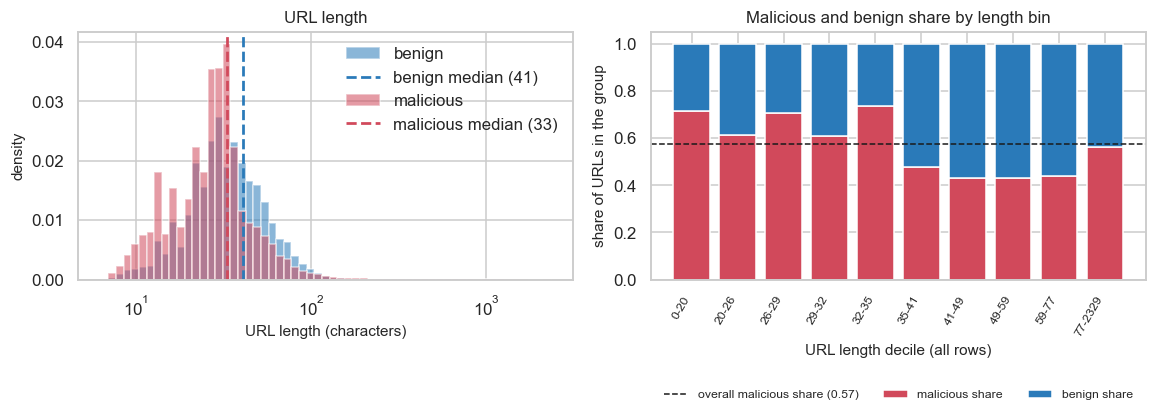

,p50,p90,p95,p99,p99.9,p100
cls,,,,,,
benign,41.0,78.0,93.0,129.0,207.0,"1,264.0"
malicious,33.0,77.0,110.0,254.0,524.2,"2,329.0"


In [12]:
# URL length: distribution with class medians, malicious and benign share across length bins, and quantiles per class
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

bins = np.logspace(0.8, np.log10(feat["url_len"].max()), 60)
medians = feat.groupby("cls")["url_len"].median()
for cls in CLASS_DIR:
    axes[0].hist(feat.loc[feat["cls"] == cls, "url_len"], bins=bins, density=True, alpha=0.55, color=COLORS[cls], label=cls)
    axes[0].axvline(medians[cls], color=COLORS[cls], ls="--", lw=1.8, label=f"{cls} median ({medians[cls]:.0f})")
axes[0].set_xscale("log"); axes[0].set_xlabel("URL length (characters)"); axes[0].set_ylabel("density"); axes[0].set_title("URL length"); axes[0].legend()

edges = feat["url_len"].quantile(np.linspace(0, 1, 11)).unique()
bin_id = pd.cut(feat["url_len"], edges, include_lowest=True)
share = feat.groupby(bin_id, observed=True)["label"].mean()
pos = list(range(len(share)))
axes[1].bar(pos, share.values, color=COLORS["malicious"], label="malicious share")
axes[1].bar(pos, 1 - share.values, bottom=share.values, color=COLORS["benign"], label="benign share")
axes[1].axhline(feat["label"].mean(), color="k", ls="--", lw=1, label=f"overall malicious share ({feat['label'].mean():.2f})")
axes[1].set_xticks(pos); axes[1].set_xticklabels([f"{int(iv.left)}-{int(iv.right)}" for iv in share.index], rotation=60, ha="right", fontsize=8)
axes[1].set_ylabel("share of URLs in the group"); axes[1].set_xlabel("URL length decile (all rows)"); axes[1].set_title("Malicious and benign share by length bin")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.4), ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

pct = [50, 90, 95, 99, 99.9, 100]
len_table = feat.groupby("cls")["url_len"].quantile([p / 100 for p in pct]).unstack()
len_table.columns = [f"p{p:g}" for p in pct]
show_table(len_table, "URL length percentiles per class (characters, all rows)", precision=1)

**Reading.** URL length is the number of characters in the string. The median benign URL is longer (41 against 33 characters, the dashed lines in the left plot), but the malicious tail is much heavier (99th percentile 254 against 129, maximum 2,329; the 99th percentile is the length that 99 out of 100 URLs stay under). The right plot sorts all URLs into ten equal-sized groups by length and splits each bar into the malicious share (red) and the benign share (blue). The malicious share moves between roughly 0.43 and 0.73 across them, against 0.57 overall, so length alone carries some signal. That is why it should be both a floor feature (an input to the simple baseline models the VAEs have to beat) and a stratification variable (results are also reported separately within length groups).

In [13]:
# Composition: scheme shares and the rate of structural flags per class, with the malicious / benign ratio
flags = ["host_is_ip", "has_port", "has_userinfo", "has_query", "non_ascii", "edge_space_or_quote", "html_entity", "bracket_artefact", "backslash"]
scheme_share = pd.crosstab(feat["cls"], feat["scheme"], normalize="index").reindex(columns=["https", "http", "other", "none"]).fillna(0)
rates = feat.groupby("cls")[flags].mean().T
comp = pd.concat([scheme_share.T.rename(index=lambda s: f"scheme: {s}"), rates.rename(index=lambda s: f"flag: {s}")])[["benign", "malicious"]]
comp["malicious / benign"] = (comp["malicious"] / comp["benign"]).replace(np.inf, np.nan)
show_table(comp, "Scheme shares and structural flag rates per class (all rows)", precision=5)

cls,benign,malicious,malicious / benign
scheme: https,0.03276,0.22005,6.71606
scheme: http,0.05347,0.40571,7.58784
scheme: other,0.00000,0.00006,NaN
scheme: none,0.91377,0.37419,0.40950
flag: host_is_ip,0.00006,0.25620,"4,079.93296"
flag: has_port,0.00038,0.19186,499.97225
flag: has_userinfo,0.00003,0.00007,2.24038
flag: has_query,0.12045,0.08785,0.72935
flag: non_ascii,0.00090,0.00014,0.15590
flag: edge_space_or_quote,0.00086,0.00639,7.46389


**Reading.** The scheme is the sharpest difference so far. 91% of benign URLs have no scheme, against 37% of malicious ones, and 41% of malicious URLs are plain `http` (not encrypted). 26% of malicious URLs use a raw IP address as the host e.g., `192.168.0.1` instead of a name (0.006% of benign), and 19% carry an explicit port (0.04% of benign). Stray quotes, HTML entities (codes such as `&amp;` that stand for a symbol), brackets and backslashes are about 7 to 17 times more common in the malicious class, but each is under 3% of rows.

In [14]:
# Host concentration: how many URLs each host holds, and how large the biggest hosts are
host_counts = {cls: feat.loc[feat["cls"] == cls, "host"].value_counts() for cls in CLASS_DIR}
rows = []
for cls, vc in host_counts.items():
    cum = vc.cumsum() / vc.sum()
    rows.append({"class": cls, "distinct hosts": len(vc), "URLs per host (mean)": round(vc.sum() / len(vc), 2),
                 "largest host share": round(vc.iloc[0] / vc.sum(), 4), "top 10 hosts share": round(vc.iloc[:10].sum() / vc.sum(), 4),
                 "hosts for 50% of URLs": int((cum < 0.5).sum() + 1), "largest host": vc.index[0]})
show_table(pd.DataFrame(rows).set_index("class"), "Host concentration per class (all rows)", precision=4)

,distinct hosts,URLs per host (mean),largest host share,top 10 hosts share,hosts for 50% of URLs,largest host
class,,,,,,
benign,"147,199",2.9200,0.0333,0.1238,"2,658",en.wikipedia.org
malicious,"366,122",1.5700,0.0179,0.0351,"78,241",87.120.115.240


**Reading.** The table counts how many URLs share the same host. Benign URLs concentrate on fewer hosts (147,199 distinct hosts, 2.9 URLs per host, and `en.wikipedia.org` alone is 3.3% of the class) than malicious URLs (366,122 hosts, 1.6 per host). This heavy head, a few hosts holding many URLs, is what makes random splits leak: if URLs from the same host land in both training and test, a model can recognize the host instead of learning what benign URLs look like (section 5). It also means a few large groups must be placed deliberately when the splits are built.

In [15]:
# Univariate separability of every URL feature: AUROC of the raw feature value (0.5 = no information)
from src.evaluate import auroc   # the same function the evaluation uses

url_num = ["has_scheme", "is_https", "url_len", "path_len", "path_depth", "n_host_labels", "host_hyphens", "n_digits", "digit_ratio", "n_upper", "n_pct", "entropy",
           "host_is_ip", "has_port", "has_userinfo", "has_query", "non_ascii", "edge_space_or_quote", "html_entity", "bracket_artefact", "backslash"]
url_auc = pd.Series({c: auroc(feat["label"], feat[c].astype(float)) for c in url_num}).rename("AUROC (malicious ranks higher)")
url_auc = url_auc.to_frame()
url_auc["distance from 0.5"] = (url_auc.iloc[:, 0] - 0.5).abs()
show_table(url_auc.sort_values("distance from 0.5", ascending=False), f"AUROC of each URL feature, malicious against benign (all {len(feat):,} rows)")

,AUROC (malicious ranks higher),distance from 0.5
has_scheme,0.770,0.270
path_len,0.257,0.243
n_host_labels,0.711,0.211
path_depth,0.292,0.208
host_is_ip,0.628,0.128
digit_ratio,0.618,0.118
n_digits,0.605,0.105
url_len,0.403,0.097
has_port,0.596,0.096
is_https,0.594,0.094


**Reading.** The table gives the AUROC of each URL feature over all 1,005,738 rows. AUROC measures how well one number can rank malicious URLs above benign ones: 0.5 means no better than chance, 1.0 means a perfect ranking, and values below 0.5 mean low values point to malicious (0.26 is as informative as 0.74 in the other direction). Ranking URLs by a single raw property already gives AUROCs far from 0.5. `has_scheme` (whether the URL starts with `http://` or similar, 0.77), `n_host_labels` (the number of dot-separated pieces in the host, 0.71) and `path_len` (the number of characters in the path, 0.26, so shorter paths are malicious) all beat URL length (0.40). A URL model that picks up the scheme or an IP host can look strong without learning anything, so the URL floor and the stratified reporting have to account for them.

## 4. Confound strength

Question: how much of the class difference can be explained by simple properties of the URL string, before looking at what the URL says? A detector that only learns URL length (`url_len`) or whether the string starts with a scheme would look strong and mean little. Such side properties are confounds. This block measures how strong they are. The numbers set which features the floor baselines use (simple models built only from these easy features, which the VAE has to beat) and which strata (groups such as by scheme or by URL length) the evaluation reports separately.

In [16]:
# Scheme and IP-host confounds on all rows: how much of the label is decided by how the string starts and what its host is
share = feat.groupby(["has_scheme", "host_is_ip"]).agg(rows=("label", "size"), malicious_share=("label", "mean"))
show_table(share, f"Malicious share by scheme and IP host (all {len(feat):,} rows)", precision=4)

rows = {}
for name, mask in {"all rows": np.ones(len(feat), bool), "no scheme": ~feat["has_scheme"].to_numpy(), "http or https": feat["has_scheme"].to_numpy(),
                   "host is not an IP": ~feat["host_is_ip"].to_numpy()}.items():
    d = feat[mask]
    rows[name] = {"rows": len(d), "malicious share": d["label"].mean(),
                  **{f"AUROC {c}": auroc(d["label"], d[c]) for c in ["url_len", "path_len", "n_host_labels", "digit_ratio"]}}
by_subset = pd.DataFrame(rows).T
by_subset["rows"] = by_subset["rows"].astype(int)
show_table(by_subset, "Malicious share and AUROC within subsets of URLs (all rows in each subset)")

,rows,malicious share,AUROC url_len,AUROC path_len,AUROC n_host_labels,AUROC digit_ratio
all rows,"1,005,738",0.572,0.403,0.257,0.711,0.618
no scheme,"608,340",0.354,0.372,0.258,0.572,0.496
http or https,"397,398",0.907,0.278,0.239,0.694,0.721
host is not an IP,"858,203",0.499,0.423,0.263,0.620,0.489


**Reading.** These tables use all 1,005,738 rows. Without a scheme (the `http://` or `https://` at the start) a URL is 35% malicious, with a scheme it is 91% malicious. A URL whose host is an IP address is malicious in 99.5% to 100% of cases (there are 5,301 such rows without a scheme and 142,234 with one). Inside each scheme group, URL length (`url_len`) still carries signal (AUROC 0.37 without a scheme, 0.28 with), with malicious URLs shorter in both.

**Decision (scheme shortcut).** The scheme (the `http://` or `https://` at the start) cannot be removed, because the QR code encodes the full string. The URL model therefore sees the string exactly as encoded, and every URL result is reported separately by scheme (stratified), together with the share of IP hosts. `has_scheme` and `host_is_ip` are also inputs of floor B, so a URL VAE has to beat a baseline that already uses them (floors are defined at the end of section 6).

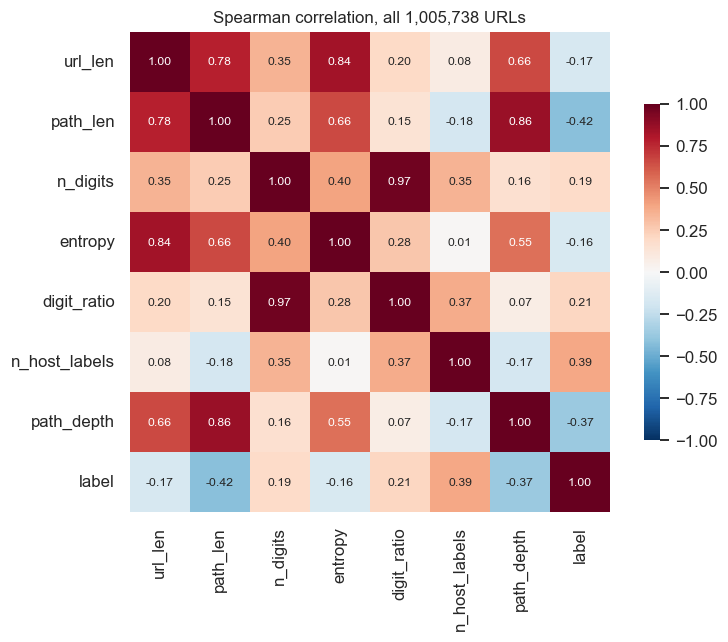

In [17]:
# How the URL properties relate to each other (Spearman, all rows). Strong off-diagonal cells mean one feature mostly restates another.
cols = ["url_len", "path_len", "n_digits", "entropy", "digit_ratio", "n_host_labels", "path_depth", "label"]
corr = feat[cols].astype(float).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": 0.7}, annot_kws={"size": 8}, ax=ax)
ax.set_title(f"Spearman correlation, all {len(feat):,} URLs")
plt.tight_layout(); plt.show()

**Reading (correlation).** The heatmap uses all 1,005,738 rows. Spearman correlation runs from -1 to 1 and measures whether two quantities rise and fall together, with 1 meaning they always keep the same order. Several URL properties mostly restate each other: URL length (`url_len`) moves with entropy (0.84), path length (`path_len`, 0.78) and path depth (0.66), path length moves with path depth (0.86), and the digit count (`n_digits`) moves with the digit ratio (`digit_ratio`, 0.97). Against the label in the last row (malicious is 1), path length (-0.42) and path depth (-0.37) are lower in malicious URLs, while the number of host labels (`n_host_labels`, 0.39) and the digit ratio (0.21) are higher. This is why `path_depth` and `entropy` are left out of the floors: they add little beyond URL length and path length.

## 5. Splitting and leakage

Question: does a random split leak, and which split do we use? Leakage means information from the test set reaching the training set, which makes test results look better than they are. The same site hosts many URLs, and a model that has seen one page of a host has partly seen the next. The check below splits the benign rows 70/15/15 at random (70% for training, 15% for validation, 15% for testing) and counts how many validation and test rows share a URL, a host or an approximate registered domain (the site name, both defined in section 3) with the training rows. It repeats the count for splits that keep every host, or every domain, on one side, and then applies the chosen rule to both classes and reports the class counts and the share of malicious rows in each split.

In [18]:
# Compare a random 70/15/15 split with grouped splits, then apply the decided rule and report counts per split
from src.splits import DEFAULT_FRACS, SPLIT_NAMES, grouped_split   # the same rule that 2_data_processing.ipynb uses

FRACS = DEFAULT_FRACS
NAMES = SPLIT_NAMES

ben = feat[feat["cls"] == "benign"].reset_index(drop=True)
mal = feat[feat["cls"] == "malicious"].reset_index(drop=True)

# random split of the benign rows
rank = np.empty(len(ben), dtype=int)
rank[np.random.default_rng(SEED).permutation(len(ben))] = np.arange(len(ben))
random_id = np.searchsorted(np.cumsum(FRACS)[:-1], rank / len(ben), side="right")
host_id = grouped_split(ben["host"], FRACS)
domain_id = grouped_split(ben["domain"], FRACS)

def share_seen_in_train(split_id, key):
    seen = set(ben.loc[split_id == 0, key])
    return {name: ben.loc[split_id == s, key].isin(seen).mean() for s, name in enumerate(NAMES) if s > 0}

rows = []
for rule, split_id in [("random", random_id), ("grouped by host", host_id), ("grouped by domain", domain_id)]:
    for key in ["url", "host", "domain"]:
        rows.append({"split rule": rule, "key": key, **share_seen_in_train(split_id, key)})
leak = pd.DataFrame(rows).set_index(["split rule", "key"])
leak.columns = [f"{c} rows sharing the key with train" for c in leak.columns]
show_table(leak, "Share of benign validation and test rows whose key also appears in the benign train split, by split rule", precision=4)

# Decided rule: benign and malicious rows are each grouped by domain and split 70/15/15 (the VAEs and floors train on the benign train rows only).
mal_id = grouped_split(mal["domain"], FRACS)
counts = pd.DataFrame({"benign": np.bincount(domain_id, minlength=3), "malicious": np.bincount(mal_id, minlength=3)}, index=NAMES)
counts["benign share of class"] = counts["benign"] / counts["benign"].sum()
counts["malicious share of class"] = counts["malicious"] / counts["malicious"].sum()
counts["malicious share of split"] = counts["malicious"] / counts[["benign", "malicious"]].sum(axis=1)
counts["largest domain, share of benign rows"] = [ben.loc[domain_id == s, "domain"].value_counts(normalize=True).iloc[0] for s in range(3)]
show_table(counts, "Rows per split under the decided rule, grouped by domain (before the 38 cross-class rows are removed)", precision=4)

,benign,malicious,benign share of class,malicious share of class,malicious share of split,"largest domain, share of benign rows"
train,"300,981","403,033",0.7000,0.7000,0.5725,0.0491
validation,"64,497","86,364",0.1500,0.1500,0.5725,0.0001
test,"64,498","86,365",0.1500,0.1500,0.5725,0.0001


**Decision (splits).** Benign and malicious rows are each split 70/15/15 into train, validation and test. The VAE and the floors train on the benign train rows only, and the malicious train rows are used only by the supervised reference. A random 70/15/15 split of the benign rows leaves 71% of validation and test rows sharing a host with a training row (78% for the approximate domain), even though no exact URL is shared. Grouping by host still leaves 18% sharing a domain, while grouping by domain leaves 0% on all three keys, so the domain is the split key. The rule: whole domains go to one split, the largest domains fill train first, and the remaining domains are shuffled and dealt to validation and test. The rule itself drops no rows. The counts above are taken before the 38 cross-class rows are removed in section 6, so the final counts are 19 benign and 19 malicious rows lower in total. The largest benign domain holds 4.9% of the benign training rows and 0.01% of the benign validation or test rows, so validation and test measure how the model does on sites it has never seen, and confidence intervals should resample whole domains, not single rows. Because both classes use the same fractions, every split is about 57% malicious (the overall share), so the AUPRC of a random scorer stays near 0.57.

## 6. Cleaning, transformations and feature candidates

The cleaning log counts every irregularity (anything unusual) found above and says what is done about it. The rule of thumb: remove rows only when the label or the identity of the row is in doubt, and keep unusual URLs, because malformed strings are part of what a malicious feed looks like and the QR code encodes exactly that string. Kept rows with an irregularity are flagged, meaning a column marks them without removing them.

In [19]:
# Cleaning log: count each irregularity per class and set the action for it
url = feat["url"]
dup_within = feat.duplicated(["cls", "url"], keep="first")
shared_set = set(feat.loc[feat["cls"] == "benign", "url"]) & set(feat.loc[feat["cls"] == "malicious", "url"])
cross = url.isin(shared_set)
empty = url.str.strip().eq("")

checks = {
    "empty or whitespace-only URL": empty,
    "exact copy of an earlier row in the same class": dup_within,
    "URL present in both classes": cross,
    "no scheme": feat["scheme"].eq("none"),
    "scheme other than http or https": feat["scheme"].eq("other"),
    "IP address as host": feat["host_is_ip"],
    "leading or trailing space or quote": feat["edge_space_or_quote"],
    "HTML entity (&amp; etc.)": feat["html_entity"],
    "bracket or markdown artefact": feat["bracket_artefact"],
    "backslash": feat["backslash"],
    "non-ASCII character": feat["non_ascii"],
}
log = pd.DataFrame({
    "benign rows": {k: int(v[feat["cls"] == "benign"].sum()) for k, v in checks.items()},
    "malicious rows": {k: int(v[feat["cls"] == "malicious"].sum()) for k, v in checks.items()},
})
log["benign %"] = (100 * log["benign rows"] / (feat["cls"] == "benign").sum()).round(3)
log["malicious %"] = (100 * log["malicious rows"] / (feat["cls"] == "malicious").sum()).round(3)
action = {
    "empty or whitespace-only URL": "drop (nothing to encode)",
    "exact copy of an earlier row in the same class": "drop the extra copies (split leakage)",
    "URL present in both classes": "drop every copy (label ambiguous)",
    "no scheme": "keep, flag. Strong shortcut, see section 4",
    "scheme other than http or https": "keep, flag",
    "IP address as host": "keep, flag",
    "leading or trailing space or quote": "keep, flag (the QR encodes it as is)",
    "HTML entity (&amp; etc.)": "keep, flag",
    "bracket or markdown artefact": "keep, flag",
    "backslash": "keep, flag",
    "non-ASCII character": "keep, decide vocabulary handling below",
}
log["action"] = pd.Series(action)
show_table(log, "Cleaning log: rows with each irregularity and the action taken (all rows)")

,benign rows,malicious rows,benign %,malicious %,action
empty or whitespace-only URL,0,0,0.000,0.000,drop (nothing to encode)
exact copy of an earlier row in the same class,0,0,0.000,0.000,drop the extra copies (split leakage)
URL present in both classes,19,19,0.004,0.003,drop every copy (label ambiguous)
no scheme,"392,898","215,442",91.377,37.419,"keep, flag. Strong shortcut, see section 4"
scheme other than http or https,0,33,0.000,0.006,"keep, flag"
IP address as host,27,"147,508",0.006,25.620,"keep, flag"
leading or trailing space or quote,368,"3,678",0.086,0.639,"keep, flag (the QR encodes it as is)"
HTML entity (& etc.),631,"13,713",0.147,2.382,"keep, flag"
bracket or markdown artefact,120,"2,762",0.028,0.480,"keep, flag"
backslash,222,"4,989",0.052,0.867,"keep, flag"


In [20]:
# Apply the removal rules and keep a reason for every dropped row
feat["drop_reason"] = ""
feat.loc[dup_within, "drop_reason"] = "duplicate_in_class"
feat.loc[cross, "drop_reason"] = "in_both_classes"
feat.loc[empty, "drop_reason"] = "empty_url"
feat["keep"] = feat["drop_reason"].eq("")

before = feat["cls"].value_counts().reindex(["benign", "malicious"])
after = feat.loc[feat["keep"], "cls"].value_counts().reindex(["benign", "malicious"])
flow = pd.DataFrame({"before": before, "dropped": before - after, "after": after})
flow["malicious share after"] = np.nan
flow.loc["total"] = [before.sum(), before.sum() - after.sum(), after.sum(), after["malicious"] / after.sum()]
show_table(flow.astype({"before": int, "dropped": int, "after": int}), "Rows before and after the removal rules", precision=4)

,before,dropped,after,malicious share after
cls,,,,
benign,"429,976",19,"429,957",NaN
malicious,"575,762",19,"575,743",NaN
total,"1,005,738",38,"1,005,700",0.5725


**Result.** Only the 38 cross-class rows are removed (19 per class), leaving 429,957 benign and 575,743 malicious URLs (57.2% malicious). Everything else is kept and flagged, including the 91% of benign URLs without a scheme, because that is how those strings were encoded in the QR code.

In [21]:
# URL maximum length: the share of URLs each candidate cut-off would truncate (kept rows)
kept = feat[feat["keep"]]

L = [64, 96, 128, 160, 256]
trunc = pd.DataFrame({l: kept.groupby("cls")["url_len"].apply(lambda s, l=l: (s > l).mean()) for l in L})
trunc.columns.name = "max length L"
show_table(trunc, "Share of kept URLs longer than L characters (cut off at L), by class", precision=4)


max length L,64,96,128,160,256
cls,,,,,
benign,0.1864,0.0429,0.0103,0.0033,0.0004
malicious,0.1444,0.0645,0.0386,0.0272,0.0097


**Decision (URL maximum length).** The cut-off is 256 characters, the largest of the values compared, chosen to cut off as few URLs as possible. It truncates 0.04% of benign and 1.0% of malicious URLs, against 1.0% and 3.9% at 128 characters. Truncating means cutting off the end of a URL. The model sees benign data only in training, so the cut-off mostly matters at test time, where truncation removes part of the heavy malicious tail. The cut-off is recorded in the config, and the share of truncated malicious test items is reported.

In [22]:
# URL vocabulary: character types in the kept URLs and what each type becomes in the URL model, then how much of the
# malicious text a vocabulary built from the most frequent benign characters would cover
kept = feat[feat["keep"]]
counts_all = Counter("".join(kept["url"]))
total_chars = sum(counts_all.values())
type_of = lambda ch: "printable ASCII (space to ~)" if 32 <= ord(ch) < 127 else ("control character (tab, line break, ...)" if ord(ch) < 128 else "non-ASCII (accents, other alphabets, symbols)")
per_type = pd.DataFrame([(type_of(ch), n) for ch, n in counts_all.items()], columns=["type", "n"]).groupby("type")["n"].agg(["size", "sum"])
per_type.columns = ["distinct characters", "occurrences"]
per_type.index.name = None
per_type["share of all characters (%)"] = 100 * per_type["occurrences"] / total_chars
per_type["URLs containing at least one"] = [int(kept["url"].str.contains(p, regex=True).sum()) for p in
                                            [r"[\x00-\x1f\x7f]", r"[^\x00-\x7f]", r"[ -~]"]]
per_type["in the URL model"] = ["unknown token", "unknown token", "its own id (95 ids)"]
per_type.loc["total"] = [per_type["distinct characters"].sum(), total_chars, 100.0, len(kept), ""]
show_table(per_type, f"Characters in the {len(kept):,} kept URLs by type, and how the URL model reads them", precision=4)

by_class = {cls: Counter("".join(kept.loc[kept["cls"] == cls, "url"])) for cls in CLASS_DIR}
benign_order = [ch for ch, _ in by_class["benign"].most_common()]
cov_m = np.cumsum([by_class["malicious"][ch] for ch in benign_order]) / sum(by_class["malicious"].values())
print(f"distinct characters: benign {len(by_class['benign'])}, malicious {len(by_class['malicious'])}, union {len(set(by_class['benign']) | set(by_class['malicious']))}")
for k in (40, 64, 96, 128):
    print(f"vocabulary of top {k:>3} benign characters: malicious OOV rate {1 - cov_m[min(k, len(cov_m)) - 1]:.2e}")


,distinct characters,occurrences,share of all characters (%),URLs containing at least one,in the URL model
"control character (tab, line break, ...)",32,"1,045",0.0023,101,unknown token
"non-ASCII (accents, other alphabets, symbols)",215,"5,611",0.0121,469,unknown token
printable ASCII (space to ~),95,"46,363,060",99.9856,"1,005,699",its own id (95 ids)
total,342,"46,369,716",100.0000,"1,005,700",


distinct characters: benign 295, malicious 268, union 342
vocabulary of top  40 benign characters: malicious OOV rate 7.39e-02
vocabulary of top  64 benign characters: malicious OOV rate 1.22e-02
vocabulary of top  96 benign characters: malicious OOV rate 4.04e-05
vocabulary of top 128 benign characters: malicious OOV rate 3.13e-05


**Decision (URL vocabulary).** The table groups every character in the kept URLs by type. The URL model has one id for each of the 95 printable ASCII symbols (letters, digits, punctuation and the space) plus a single unknown token. Control characters (invisible codes such as tab) and non-ASCII characters (accented letters, other alphabets and symbols) all become the unknown token. Together they are 0.014% of all characters (6,656 of 46,369,716) and appear in 482 URLs (0.05% of the kept URLs). Giving the 215 distinct non-ASCII characters their own ids would add 215 ids that are each seen about 26 times on average in 46 million characters, so a single unknown token loses very little and keeps the vocabulary small (97 ids, counting padding). The cell below the table also checks coverage: across both classes there are 342 distinct characters, but a vocabulary of only the 96 most frequent benign characters would leave about 4 in 100,000 malicious characters unknown (4.0e-05), so the unknown token is rarely needed even for malicious URLs.


In [23]:
# Feature candidates: measured separability, and the role each one plays in the evaluation
roles = {
    "has_scheme": "strongest URL-level shortcut. Report stratified by it, and use it in floor B",
    "host_is_ip": "near-deterministic shortcut (see the table above). Report as a share, and use it in floor B",
    "n_host_labels": "floor B feature, partly a restatement of host type",
    "path_len": "floor B feature, correlated with URL length",
    "path_depth": "not used in the floors, correlated with URL length",
    "url_len": "feature of floors A and B, and length-bin stratum",
    "digit_ratio": "floor B feature",
    "entropy": "not used in the floors, correlated with URL length",
}
cand = url_auc.loc[list(roles)].iloc[:, [0]]
cand.columns = ["AUROC"]
cand["role"] = pd.Series(roles)
cand["AUROC"] = cand["AUROC"].round(3)
show_table(cand.sort_values("AUROC", key=lambda s: (s - 0.5).abs(), ascending=False),
           f"Candidate features: AUROC on all {len(feat):,} rows and role in the evaluation")

,AUROC,role
has_scheme,0.770,"strongest URL-level shortcut. Report stratified by it, and use it in floor B"
path_len,0.257,"floor B feature, correlated with URL length"
n_host_labels,0.711,"floor B feature, partly a restatement of host type"
path_depth,0.292,"not used in the floors, correlated with URL length"
host_is_ip,0.628,"near-deterministic shortcut (see the table above). Report as a share, and use it in floor B"
digit_ratio,0.618,floor B feature
url_len,0.403,"feature of floors A and B, and length-bin stratum"
entropy,0.407,"not used in the floors, correlated with URL length"


### Floor definitions

A floor is a simple baseline that uses only a few easy-to-measure properties and no learned text model. It shows how much of the class difference those properties explain, so a VAE only counts as having learned something if it does better. Each floor is a Gaussian (bell-shaped) distribution fitted to benign training items only. An item's score is its Mahalanobis distance from the benign mean, meaning how far its features lie from typical benign values, scaled by their spread and correlation. With one feature this is the absolute z-score. Higher scores mean more likely malicious, the same convention as the VAE scores. Because `host_is_ip` is almost constant among benign URLs (0.006% have an IP host), the covariance gets a small ridge term so the distance stays finite.

There are two floors.

- **Floor A (minimal, headline).** URL length (`url_len`). Floor A is the headline floor in the main results table.
- **Floor B (extended).** Adds the shortcut and structure features from the candidate table above: `has_scheme`, `host_is_ip`, `n_host_labels`, `path_len` and `digit_ratio`. It is a harder bar because it includes the strongest URL-level shortcuts, and it is reported alongside floor A. `path_depth` and `entropy` are left out because the table marks them as correlated with URL length.

Stratified reporting from section 4 applies to every model, floors included: AUROC within scheme strata and within URL-length bins. The IP-host group has almost no benign rows (0.006% of benign URLs), so it is reported as a share and no AUROC is computed for it.

In [24]:
# Floor definitions (from src/floors.py, the same dict the floor notebook fits), with a check that every feature exists
from src.floors import FLOORS

rows = []
for model, spec in FLOORS.items():
    missing = [c for c in spec["features"] if c not in feat.columns]
    assert not missing, f"{model}: missing columns {missing}"
    rows.append({"floor": model, "features": ", ".join(spec["features"]),
                 "score": "absolute z-score" if spec["score"] == "abs_z" else "Mahalanobis distance",
                 "fitted on": "benign train split only"})
show_table(pd.DataFrame(rows).set_index("floor"), "Floor definitions: features, score and fitting data")


,features,score,fitted on
floor,,,
floorA_url,url_len,absolute z-score,benign train split only
floorB_url,"url_len, has_scheme, host_is_ip, n_host_labels, path_len, digit_ratio",Mahalanobis distance,benign train split only


## Save processed

This cell writes `data/processed/manifest.csv.gz`, one row per source row with the `keep` flag and drop reason, the URL features, the host and domain keys used for grouping and the normalised URL key, so later steps can filter instead of re-deriving. It does not assign rows to train, validation or test: `2_data_processing.ipynb` applies the rule from section 5 and builds the items table. `data/processed/` is git-ignored, meaning version control does not track it.


In [25]:
# Save the manifest (one row per URL with keep flag and features)
manifest = feat.drop(columns=["scheme"]).assign(scheme=feat["scheme"])
manifest_path = PROC_DIR / "manifest.csv.gz"
manifest.to_csv(manifest_path, index=False)
print("saved", manifest_path, manifest.shape)


saved c:\Users\joetn\convolutional_vae_quishing\data\processed\manifest.csv.gz (1005738, 32)
